# Uncertainty in `optimex`: Monte Carlo over the optimization

LCA data are uncertain, and Brightway stores that uncertainty as distributions on
exchanges, parameters, and background data. This notebook carries those
distributions into the optimization. `optimex.uncertainty` draws many complete sets
of optimization inputs, one per Monte Carlo sample, and either

1. **optimizes every sample**, which shows how much the optimal pathway and its
   impact depend on the uncertain data, or
2. **evaluates a fixed design in every sample**, which shows how robust a given
   pathway is, for example the deterministic optimum.

The example first minimizes climate impact and then adds uncertain prices and the
cost objective on top. Four sources of uncertainty are covered:

| Source | Where it is defined | Example here |
|---|---|---|
| Foreground exchanges | Uncertainty fields on the exchange | Direct CO2 of both routes |
| Brightway parameters | Uncertain parameters used by exchange formulas | Efficiency of the advanced route |
| Background databases | Uncertainty fields on background exchanges | CO2 of the purchased inputs |
| Prices | Uncertainty columns in `set_market_prices` | Prices of all purchased inputs |

All numbers are synthetic and chosen to show the workflow.

!!! note "Why Monte Carlo and not stochastic programming?"
    Two-stage stochastic programming assumes the uncertainty is revealed after
    the first decisions: build now, learn the true values, then adapt operation.
    Most LCA uncertainty is never revealed. Nobody observes the true emission
    factor of a background process, so letting operation adapt to it would be
    too optimistic. Monte Carlo answers the questions that matter here
    directly: how often a technology is the best choice, and how a chosen
    pathway performs over the plausible range of data.

## 1. Setup

Use a notebook kernel with this repository's `optimex`, Brightway,
`bw_temporalis`, Matplotlib, and the free HiGHS solver (`pip install highspy`)
installed; see the [installation guide](../docs/content/installation.md). No
ecoinvent data are needed.

HiGHS, like Gurobi, lets `optimex` keep one solver model for all Monte Carlo
samples and only update what changes. Other solvers, such as GLPK, work too, but
then every sample is built from scratch and `optimex` warns about it.

The notebook **deletes and recreates** the Brightway project
`optimex_uncertainty_example` on every run, so parameters from earlier runs cannot
linger. Do not store other work in that project.

In [1]:
import math
import sys
import warnings
from datetime import datetime

warnings.filterwarnings("ignore", message="No fast sparse solver found")
warnings.filterwarnings("ignore", message=r"urllib3 .* doesn't match a supported version!")
warnings.filterwarnings("ignore", message=r"\s*It seems like you have an ARM architecture")

import bw2data as bd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bw_temporalis import TemporalDistribution
from loguru import logger

from optimex import converter, lca_processor, optimizer, postprocessing, uncertainty
from optimex.economics import set_market_prices

logger.remove()
logger.add(sys.stderr, level="WARNING")

PROJECT = "optimex_uncertainty_example"
if PROJECT in bd.projects:
    bd.projects.delete_project(PROJECT, delete_dir=True)
bd.projects.set_current(PROJECT)

SOLVER = "highs"
COLORS = {"conventional": "#657783", "advanced": "#27836c"}

## 2. Product system and its uncertainty

The system is the one from the [basic cost example](basic_example_econ.ipynb):
10 product units per year from 2025 to 2034, supplied by a conventional or an
advanced process. One installed unit supplies 1 product unit per year for five
years. Both routes buy construction at installation and a route-specific input
during operation, and both emit CO2 directly.

The advanced route is cleaner on paper, but it is a new technology, so its data
are less certain:

| Quantity | Deterministic value | Distribution |
|---|---|---|
| Direct CO2, conventional | 4 kg per unit and year | Normal, 5% standard deviation |
| Direct CO2, advanced | 3 kg per unit and year | Lognormal, geometric standard deviation (GSD) 1.5 |
| Efficiency, advanced | 0.8 | Triangular between 0.6 and 0.9, mode 0.8 |
| Advanced input per unit and year | 1 / efficiency | From the efficiency parameter |
| Background CO2 per unit of input | See below | Lognormal, GSD 1.1 to 1.4 |

Brightway describes a distribution with the fields `uncertainty type` (a
`stats_arrays` id: 2 lognormal, 3 normal, 4 uniform, 5 triangular), `loc`,
`scale`, `minimum`, and `maximum`. For a lognormal distribution, `loc` is the
natural logarithm of the median, which is also the deterministic amount, and
`scale` is the natural logarithm of the GSD.

In [2]:
years = np.arange(2025, 2035)
lifetime = 5
annual_demand = 10.0
background_databases = {2025: "background_2025", 2034: "background_2034"}

background_co2 = pd.DataFrame([
    {"input": "construction", "kg CO2/unit in 2025": 1.0,
     "kg CO2/unit in 2034": 1.0, "GSD": 1.2},
    {"input": "conventional_input", "kg CO2/unit in 2025": 2.0,
     "kg CO2/unit in 2034": 2.0, "GSD": 1.1},
    {"input": "advanced_input", "kg CO2/unit in 2025": 1.0,
     "kg CO2/unit in 2034": 0.5, "GSD": 1.4},
]).set_index("input")
background_co2

,kg CO2/unit in 2025,kg CO2/unit in 2034,GSD
input,,,
construction,1.0,1.0,1.2
conventional_input,2.0,2.0,1.1
advanced_input,1.0,0.5,1.4


### Background databases

The two background snapshots have the same structure, and the CO2 of the advanced
input halves by 2034. Each CO2 exchange carries a lognormal distribution.

In [3]:
%%capture
bd.Database("biosphere3").write({
    ("biosphere3", "CO2"): {
        "name": "carbon dioxide", "unit": "kg",
        "type": bd.labels.biosphere_node_default,
    },
})
method = ("illustrative", "climate_change")
bd.Method(method).register(unit="kg CO2-eq")
bd.Method(method).write([(("biosphere3", "CO2"), 1.0)])

for year, db_name in background_databases.items():
    data = {}
    for name, row in background_co2.iterrows():
        co2 = row[f"kg CO2/unit in {year}"]
        data[(db_name, name)] = {
            "name": name, "reference product": name,
            "location": "GLO", "unit": "unit",
            "type": bd.labels.chimaera_node_default,
            "exchanges": [
                {"input": (db_name, name), "amount": 1.0,
                 "type": bd.labels.production_edge_default},
                {"input": ("biosphere3", "CO2"), "amount": co2,
                 "type": bd.labels.biosphere_edge_default,
                 "uncertainty type": 2, "loc": math.log(co2),
                 "scale": math.log(row["GSD"])},
            ],
        }
    db = bd.Database(db_name)
    db.write(data)
    db.metadata["representative_time"] = datetime(year, 1, 1).isoformat()
    db.register()

### Foreground processes

Exchange amounts are full-lifetime quantities, as in the other examples. The
direct CO2 exchanges carry their own distributions. The amount of advanced input is
not a number but the formula `advanced_input_demand`, a parameter defined below.

In [4]:
%%capture
installation_td = TemporalDistribution(
    date=np.array([0], dtype="timedelta64[Y]"), amount=np.array([1.0]),
)
operation_td = TemporalDistribution(
    date=np.arange(lifetime).astype("timedelta64[Y]"),
    amount=np.full(lifetime, 1.0 / lifetime),
)


def production(amount):
    return {"input": ("foreground", "product"), "amount": amount,
            "type": bd.labels.production_edge_default,
            "temporal_distribution": operation_td, "operation": True}


def purchase(name, amount, operation, **extra):
    return {"input": ("background_2025", name), "amount": amount,
            "type": bd.labels.consumption_edge_default, "operation": operation,
            "temporal_distribution": operation_td if operation else installation_td,
            **extra}


def direct_co2(amount, **uncertainty_fields):
    return {"input": ("biosphere3", "CO2"), "amount": amount,
            "type": bd.labels.biosphere_edge_default,
            "temporal_distribution": operation_td, "operation": True,
            **uncertainty_fields}


conventional_co2 = 4.0 * lifetime
advanced_co2 = 3.0 * lifetime
foreground_data = {
    ("foreground", "product"): {
        "name": "Product", "unit": "unit", "type": bd.labels.product_node_default,
    },
    ("foreground", "conventional"): {
        "name": "Conventional", "location": "GLO",
        "type": bd.labels.process_node_default,
        "operation_time_limits": (0, lifetime - 1),
        "exchanges": [
            production(float(lifetime)),
            purchase("construction", 1.0, operation=False),
            purchase("conventional_input", float(lifetime), operation=True),
            direct_co2(conventional_co2, **{
                "uncertainty type": 3, "loc": conventional_co2,
                "scale": 0.05 * conventional_co2,
            }),
        ],
    },
    ("foreground", "advanced"): {
        "name": "Advanced", "location": "GLO",
        "type": bd.labels.process_node_default,
        "operation_time_limits": (0, lifetime - 1),
        "exchanges": [
            production(float(lifetime)),
            purchase("construction", 2.0, operation=False),
            purchase("advanced_input", lifetime / 0.8, operation=True,
                     formula="advanced_input_demand"),
            direct_co2(advanced_co2, **{
                "uncertainty type": 2, "loc": math.log(advanced_co2),
                "scale": math.log(1.5),
            }),
        ],
    },
}
bd.Database("foreground").write(foreground_data)

### Parameters

The efficiency of the advanced route is an uncertain **project parameter**. An
**activity parameter** turns it into the input demand over the lifetime, and the
exchange formula refers to that activity parameter. `optimex` evaluates these
formulas for every sample, so the uncertainty of the parameter reaches the
exchange.

`bd.parameters.recalculate()` writes the deterministic amounts to the exchanges,
which the deterministic inputs are built from.

In [5]:
bd.parameters.new_project_parameters([
    {"name": "lifetime", "amount": lifetime},
    {"name": "advanced_efficiency", "amount": 0.8,
     "uncertainty type": 5, "loc": 0.8, "minimum": 0.6, "maximum": 0.9},
])
bd.parameters.new_activity_parameters([
    {"name": "advanced_input_demand", "formula": "lifetime / advanced_efficiency",
     "database": "foreground", "code": "advanced"},
], group="advanced")
bd.parameters.add_exchanges_to_group(
    "advanced", bd.get_node(database="foreground", code="advanced")
)
bd.parameters.recalculate()

advanced = bd.get_node(database="foreground", code="advanced")
{exc.input["name"]: exc["amount"] for exc in advanced.technosphere()}

{'construction': 2.0, 'advanced_input': 6.25}

## 3. The deterministic optimum

The inputs are built exactly as without uncertainty. The deterministic optimum is
the reference for everything below.

In [6]:
%%capture
demand_td = TemporalDistribution(
    date=np.array([f"{year}-01-01" for year in years], dtype="datetime64[s]"),
    amount=np.full(len(years), annual_demand),
)
config = lca_processor.LCAConfig(
    demand={bd.get_node(database="foreground", code="product"): demand_td},
    temporal={
        "start_date": datetime(2025, 1, 1),
        "temporal_resolution": "year",
        "database_dates": {
            name: datetime(year, 1, 1) for year, name in background_databases.items()
        },
    },
    characterization_methods=[{
        "category_name": "climate_change", "brightway_method": method,
    }],
    background_inventory={"calculation_method": "sequential"},
)
processor = lca_processor.LCADataProcessor(config)
manager = converter.ModelInputManager()
inputs = manager.parse_from_lca_processor(processor)

climate_model = optimizer.create_model(
    inputs, name="climate_deterministic", objective_category="climate_change",
)
climate_model, climate_deterministic, _ = optimizer.solve_model(
    climate_model, solver_name=SOLVER, tee=False,
)

In [7]:
def new_units(model):
    installation = postprocessing.PostProcessor(model).get_installation()
    return installation.loc[installation.abs().sum(axis=1) > 1e-6].round(2)


print(f"Deterministic climate minimum: {climate_deterministic:.1f} kg CO2-eq")
new_units(climate_model)

Deterministic climate minimum: 433.8 kg CO2-eq


Process,advanced,conventional
Time,,
2025,10.0,0.0
2030,10.0,0.0


With the deterministic data, the advanced route wins: ten units are installed in
2025 and replaced in 2030.

## 4. Drawing samples

`UncertaintySampler` collects every uncertain quantity of the product system.
`summary()` lists what it found.

In [8]:
sampler = uncertainty.UncertaintySampler(processor, inputs)
sampler.summary().fillna("")

,source,quantity,amount,uncertainty type,loc,scale,minimum,maximum,formula
0,exchanges,advanced <- CO2,15.0,2.0,2.70805,0.405465,,,
1,exchanges,conventional <- CO2,20.0,3.0,20.0,1.0,,,
2,parameters,project:advanced_efficiency,0.8,5.0,0.8,,0.6,0.9,
3,parameterized exchanges,advanced <- advanced_input,6.25,,,,,,advanced_input_demand
4,background,background_2025,,,,,,,
5,background,background_2034,,,,,,,


`sample()` draws complete sets of optimization inputs. A sample is a copy of
`inputs` in which only the uncertain values differ, so limits, discounting, and
any other overrides carry over. `samples.values` holds the sampled values of the
explicitly uncertain quantities, one row per sample.

The draws come from Brightway's own Monte Carlo machinery:

- foreground exchanges: `matrix_utils` builds the foreground matrices from the
  processed datapackage with `use_distributions=True` and redraws them with
  `next()`, as `bw2calc.LCA(..., use_distributions=True)` does;
- parameters: `stats_arrays` draws the uncertain parameters,
  `bw2parameters` propagates them through the formulas, and the resulting
  exchange amounts enter the foreground matrices as a `bw_processing` array
  datapackage;
- background databases: a `bw2calc` Monte Carlo LCA per database.

Pre-sampled datapackages, for example of correlated exchanges, can be layered on
top with `foreground_datapackages=` and `background_datapackages=`.

Each quantity is drawn **once per sample** and applies wherever it is used: a
direct CO2 exchange drawn 20% high is 20% high at every process time, in every
vintage, and in every year. The two background snapshots are sampled with
common random numbers, so the same exchange takes the same quantile in both.

In [9]:
%%capture
N_SAMPLES = 200
samples = sampler.sample(N_SAMPLES, seed=42)

In [10]:
samples.values.describe().T.round(3)

count    mean    std  \
source                  quantity                                            
parameters              project:advanced_efficiency  200.0   0.770  0.066   
parameterized exchanges advanced <- advanced_input   200.0   6.545  0.599   
exchanges               advanced <- CO2              200.0  16.846  7.164   
                        conventional <- CO2          200.0  20.060  1.030   

                                                        min     25%     50%  \
source                  quantity                                              
parameters              project:advanced_efficiency   0.611   0.724   0.783   
parameterized exchanges advanced <- advanced_input    5.646   6.059   6.388   
exchanges               advanced <- CO2               5.469  11.511  15.238   
                        conventional <- CO2          17.818  19.318  20.067   

                                                        75%     max  
source                  quantity                                     
parameters              project:advanced_efficiency   0.825   0.886  
parameterized exchanges advanced <- advanced_input    6.906   8.179  
exchanges               advanced <- CO2              21.041  44.393  
                        conventional <- CO2          20.780  22.469

The mean of the lognormal direct CO2 of the advanced route is above its
deterministic value, the median: lognormal distributions are skewed to the right.

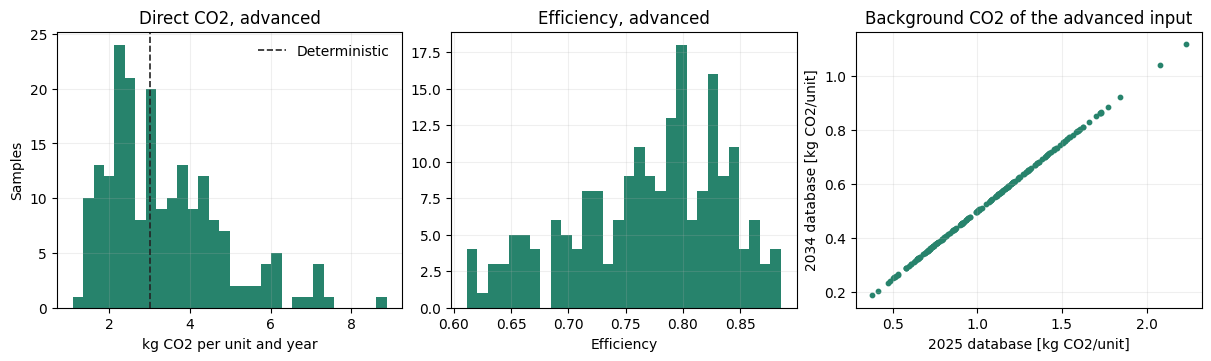

In [11]:
def background_co2_of(flow, db_name):
    return np.array([
        s.background_inventory[db_name, flow, "CO2"] for s in samples
    ])


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
axes[0].hist(samples.values["exchanges", "advanced <- CO2"] / lifetime,
             bins=30, color=COLORS["advanced"])
axes[0].axvline(advanced_co2 / lifetime, color="#242424", linestyle="--",
                linewidth=1.2, label="Deterministic")
axes[0].set(title="Direct CO2, advanced", xlabel="kg CO2 per unit and year",
            ylabel="Samples")
axes[0].legend(frameon=False)

axes[1].hist(samples.values["parameters", "project:advanced_efficiency"],
             bins=30, color=COLORS["advanced"])
axes[1].set(title="Efficiency, advanced", xlabel="Efficiency")

axes[2].scatter(background_co2_of("advanced_input", "background_2025"),
                background_co2_of("advanced_input", "background_2034"),
                s=10, color=COLORS["advanced"])
axes[2].set(title="Background CO2 of the advanced input",
            xlabel="2025 database [kg CO2/unit]",
            ylabel="2034 database [kg CO2/unit]")
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

The right panel shows the common random numbers: a sample with high background
emissions in 2025 also has high emissions in 2034. Sampling the snapshots
independently would let the data jump between years, which would make the timing
of investments look more uncertain than it is.

## 5. Monte Carlo over the optimum

`solve_samples` optimizes every sample on its own. Keyword arguments go to
`create_model`, so the objective is chosen as usual. With HiGHS or Gurobi, the
samples share one solver model: only the coefficients that differ are updated,
and each solve starts from the previous solution (`persistent="auto"`).

In [12]:
%%capture
climate_optima = uncertainty.solve_samples(
    samples, objective_category="climate_change", solver_name=SOLVER,
)

In [13]:
climate_optima.summary().round(1)

,mean,std,q0.05,q0.5,q0.95,feasible
objective,462.2,111.8,289.3,456.6,626.6,200
impact: climate_change,462.2,111.8,289.3,456.6,626.6,200


The results also hold the installation, operation, and production of every
sample. A linear program puts its solution on a vertex, so in each sample one
route usually takes the whole cohort. How often each route is chosen is therefore
the meaningful result, more than the mean installation.

In [14]:
def advanced_share(results, cohorts=(2025, 2030)):
    # Share of samples in which the advanced route gets most of a cohort's units
    installation = results.installation
    built = installation[["advanced", "conventional"]].sum(axis=1)
    mostly_advanced = installation["advanced"] > 0.5 * built
    share = mostly_advanced[built > 1e-6].groupby(level="Time").mean()
    return share.reindex(list(cohorts))


pd.DataFrame({
    "Share of samples choosing the advanced route": advanced_share(climate_optima),
}).rename_axis("Installation cohort").style.format("{:.0%}")

,Share of samples choosing the advanced route
Installation cohort,
2025,82%
2030,86%


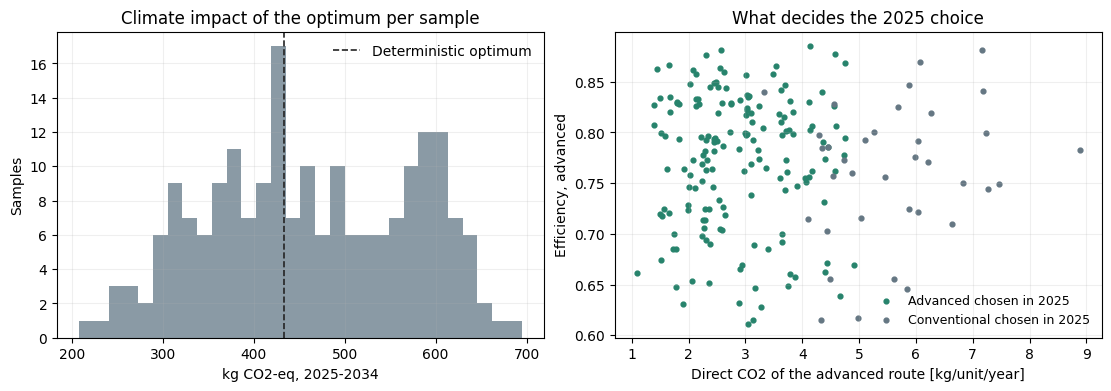

In [15]:
efficiency = samples.values["parameters", "project:advanced_efficiency"]
advanced_direct = samples.values["exchanges", "advanced <- CO2"] / lifetime
installation_2025 = climate_optima.installation.xs(2025, level="Time")
chose_advanced = installation_2025["advanced"] > 0.5 * installation_2025.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].hist(climate_optima.objective, bins=30, color="#8a9aa5")
axes[0].axvline(climate_deterministic, color="#242424", linestyle="--",
                linewidth=1.2, label="Deterministic optimum")
axes[0].set(title="Climate impact of the optimum per sample",
            xlabel="kg CO2-eq, 2025-2034", ylabel="Samples")
axes[0].legend(frameon=False)

for route, mask in (("advanced", chose_advanced), ("conventional", ~chose_advanced)):
    axes[1].scatter(advanced_direct[mask], efficiency[mask], s=12,
                    color=COLORS[route], label=f"{route.capitalize()} chosen in 2025")
axes[1].set(title="What decides the 2025 choice",
            xlabel="Direct CO2 of the advanced route [kg/unit/year]",
            ylabel="Efficiency, advanced")
axes[1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

The climate impact of the optimum spreads widely, from about 290 to 630 kg
CO2-eq between the 5th and 95th percentiles, around the deterministic 434 kg
CO2-eq. Its mean is higher than the deterministic value because the lognormal
direct emissions of the advanced route are skewed to the right.

The choice is more robust than the impact. The advanced route is optimal for the
2025 cohort in 82% of the samples and for the 2030 cohort in 86%: by then its
background input is cleaner. The right panel shows what decides: the
conventional route wins when the direct emissions of the advanced route are
high, above roughly 4.5 kg per unit and year, and earlier when its efficiency is
low.

## 6. How robust is the deterministic design?

The deterministic optimum is a single pathway. `evaluate_design` fixes it in every
sample and reports what it achieves there. `fix="pathway"` fixes installation and
operation, the right choice for LCA data: the operator never learns the true
emission factors, so the plants run as planned. `fix="installation"` would only
fix the capacity and re-optimize its operation per sample, which suits
uncertainty the operator observes, such as prices.

The **regret** of a sample is how much worse the fixed design does than the best
pathway for that sample.

In [16]:
%%capture
climate_design = uncertainty.evaluate_design(
    climate_model, samples, fix="pathway", objective_category="climate_change",
    solver_name=SOLVER,
)

In [17]:
regret = climate_design.objective - climate_optima.objective
pd.Series({
    "Samples in which another pathway would be better": f"{(regret > 1e-6).mean():.0%}",
    "Mean regret [kg CO2-eq]": f"{regret.mean():.1f}",
    "95th percentile of regret [kg CO2-eq]": f"{regret.quantile(0.95):.1f}",
    "Largest regret [kg CO2-eq]": f"{regret.max():.1f}",
    "Mean impact, fixed design [kg CO2-eq]": f"{climate_design.objective.mean():.1f}",
    "Mean impact, best pathway per sample [kg CO2-eq]": f"{climate_optima.objective.mean():.1f}",
}).to_frame("Deterministic design")

,Deterministic design
Samples in which another pathway would be better,18%
Mean regret [kg CO2-eq],19.4
95th percentile of regret [kg CO2-eq],184.7
Largest regret [kg CO2-eq],309.9
"Mean impact, fixed design [kg CO2-eq]",481.7
"Mean impact, best pathway per sample [kg CO2-eq]",462.2


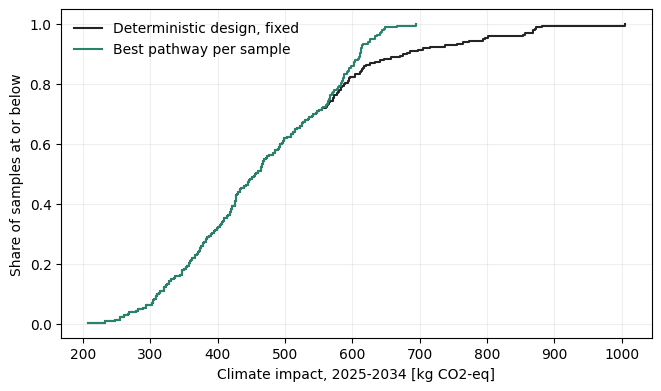

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
for label, values, color in (
    ("Deterministic design, fixed", climate_design.objective, "#242424"),
    ("Best pathway per sample", climate_optima.objective, "#27836c"),
):
    ordered = np.sort(values)
    ax.step(ordered, np.arange(1, len(ordered) + 1) / len(ordered),
            where="post", color=color, label=label)
ax.set(xlabel="Climate impact, 2025-2034 [kg CO2-eq]",
       ylabel="Share of samples at or below")
ax.grid(alpha=0.2)
ax.legend(frameon=False)
plt.show()

The deterministic design is the best choice in 82% of the samples. In the other
18%, a pathway with conventional capacity would have emitted less, by up to
310 kg CO2-eq in the worst sample. The two curves coincide up to about 560 kg
CO2-eq and separate in the upper tail: the deterministic design carries the risk
that the direct emissions of the advanced route turn out high.

The mean regret, 19 kg CO2-eq, is the expected value of perfect information:
what knowing the true data before deciding would be worth. It is small compared
with the spread of the impact itself, so better data would mostly narrow the
range of outcomes rather than change the decision.

## 7. Adding costs

Prices are uncertain too. `set_market_prices` accepts the same Brightway
uncertainty columns as exchanges. A missing `loc` is derived from the price: its
logarithm for a lognormal distribution, the price itself otherwise. The
distribution is written next to the price, to the node attribute
`market_price_uncertainty`.

Prices are drawn as **one quantile per product and sample**, shared by all
background snapshots: a sample in which the advanced input is expensive in 2025 is
also expensive in 2034. The spread may differ between snapshots, and here it grows
towards 2034, since prices further ahead are less certain.

In [19]:
price_assumptions = pd.DataFrame([
    {"name": "construction", "year": 2025, "price": 4.0,
     "uncertainty type": 3, "scale": 0.4},
    {"name": "construction", "year": 2034, "price": 4.0,
     "uncertainty type": 3, "scale": 0.4},
    {"name": "conventional_input", "year": 2025, "price": 5.0,
     "uncertainty type": 2, "scale": math.log(1.15)},
    {"name": "conventional_input", "year": 2034, "price": 5.0,
     "uncertainty type": 2, "scale": math.log(1.3)},
    {"name": "advanced_input", "year": 2025, "price": 6.0,
     "uncertainty type": 2, "scale": math.log(1.15)},
    {"name": "advanced_input", "year": 2034, "price": 3.0,
     "uncertainty type": 2, "scale": math.log(1.5)},
]).assign(location="GLO")
set_market_prices(price_assumptions, background_databases)
price_assumptions

,name,year,price,uncertainty type,scale,location
0,construction,2025,4.0,3,0.400000,GLO
1,construction,2034,4.0,3,0.400000,GLO
2,conventional_input,2025,5.0,2,0.139762,GLO
3,conventional_input,2034,5.0,2,0.262364,GLO
4,advanced_input,2025,6.0,2,0.139762,GLO
5,advanced_input,2034,3.0,2,0.405465,GLO


In [20]:
bd.get_node(database="background_2034", name="advanced_input")["market_price_uncertainty"]

{'uncertainty type': 2, 'loc': 1.0986122886681098, 'scale': 0.4054651081081644}

The processor is rebuilt with `price_attribute`, and the discount rate is added.
The background inventories are cached, so this is quick. The new sampler finds the
prices in addition to everything above.

In [21]:
%%capture
cost_processor = lca_processor.LCADataProcessor(
    config.model_copy(update={"price_attribute": "market_price"})
)
cost_manager = converter.ModelInputManager()
cost_manager.parse_from_lca_processor(cost_processor)
cost_inputs = cost_manager.override(discount_rate=0.03, discount_reference_year=2025)

cost_sampler = uncertainty.UncertaintySampler(cost_processor, cost_inputs)
cost_samples = cost_sampler.sample(N_SAMPLES, seed=42)

Every source draws from its own random stream. With the same seed, adding prices
therefore leaves the environmental draws exactly as before, so the samples of the
two objectives describe the same uncertain world:

In [22]:
pd.testing.assert_frame_equal(
    cost_samples.values.drop(columns="prices", level="source"), samples.values,
)
cost_samples.values["prices"].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
quantity,,,,,,,,
advanced_input @ background_2025,200.0,6.16,0.90,3.98,5.61,6.05,6.75,9.14
advanced_input @ background_2034,200.0,3.42,1.47,0.91,2.47,3.08,4.21,10.18
construction @ background_2025,200.0,4.05,0.36,3.00,3.79,4.05,4.32,4.85
construction @ background_2034,200.0,4.05,0.36,3.00,3.79,4.05,4.32,4.85
conventional_input @ background_2025,200.0,5.10,0.70,3.58,4.58,5.06,5.56,7.29
conventional_input @ background_2034,200.0,5.27,1.36,2.67,4.24,5.12,6.10,10.16


### Cost minimum

In [23]:
%%capture
cost_model = optimizer.create_model(cost_inputs, name="cost_deterministic", objective="cost")
cost_model, cost_deterministic, _ = optimizer.solve_model(
    cost_model, solver_name=SOLVER, tee=False,
)
cost_optima = uncertainty.solve_samples(cost_samples, objective="cost", solver_name=SOLVER)

In [24]:
print(f"Deterministic cost minimum: {cost_deterministic:.1f} EUR_2025 (present value)")
display(new_units(cost_model))
display(cost_optima.summary().round(1))
pd.DataFrame({
    "Share of samples choosing the advanced route": advanced_share(cost_optima),
}).rename_axis("Installation cohort").style.format("{:.0%}")

Deterministic cost minimum: 513.8 EUR_2025 (present value)


Process,advanced,conventional
Time,,
2025,0.0,10.0
2030,0.0,10.0


,mean,std,q0.05,q0.5,q0.95,feasible
objective,510.2,70.3,401.2,511.5,625.9,200
impact: climate_change,592.6,65.7,457.8,603.5,676.9,200
cost (discounted),510.2,70.3,401.2,511.5,625.9,200


,Share of samples choosing the advanced route
Installation cohort,
2025,3%
2030,34%


With the deterministic prices, the conventional route is cheaper for both
cohorts. For 2025 this holds in almost every sample (advanced in 3%). For the
2030 cohort, the advanced input has become cheaper and its price is more
uncertain, and the advanced route is the cheaper choice in 34% of the samples.
The cost minimum emits clearly more than the climate minimum: about 590 kg
CO2-eq on average.

### Cost minimum under a climate budget

A cumulative climate budget of **520 kg CO2-eq** lies between the climate minimum
and the climate impact of the cost minimum. Under deterministic data, the cost
minimum within the budget uses the budget exactly. Two questions follow under
uncertainty:

1. In how many samples does *any* pathway stay within the budget?
2. If the deterministic design is built, how often does it actually stay within
   the budget?

Limits can be added to existing samples with `model_copy`, without sampling again.

In [25]:
%%capture
climate_budget = 520.0
budget = {"cumulative_category_impact_limits": {"climate_change": climate_budget}}

budget_model = optimizer.create_model(
    cost_manager.override(**budget), name="cost_with_budget", objective="cost",
)
budget_model, budget_cost, _ = optimizer.solve_model(
    budget_model, solver_name=SOLVER, tee=False,
)

budget_optima = uncertainty.solve_samples(
    [sample.model_copy(update=budget) for sample in cost_samples],
    objective="cost", solver_name=SOLVER,
)
budget_design = uncertainty.evaluate_design(
    budget_model, cost_samples, fix="pathway", objective="cost", solver_name=SOLVER,
)

In [26]:
design_climate = budget_design.impacts["climate_change"]
pd.Series({
    "Deterministic cost within the budget [EUR_2025]": f"{budget_cost:.1f}",
    "Samples in which some pathway meets the budget": f"{budget_optima.feasible.mean():.0%}",
    "Samples in which the deterministic design meets it": f"{(design_climate <= climate_budget + 1e-6).mean():.0%}",
    "Mean climate impact of the design [kg CO2-eq]": f"{design_climate.mean():.1f}",
    "95th percentile [kg CO2-eq]": f"{design_climate.quantile(0.95):.1f}",
}).to_frame("Budget of 520 kg CO2-eq")

,Budget of 520 kg CO2-eq
Deterministic cost within the budget [EUR_2025],532.0
Samples in which some pathway meets the budget,66%
Samples in which the deterministic design meets it,44%
Mean climate impact of the design [kg CO2-eq],542.1
95th percentile [kg CO2-eq],685.8


Under uncertainty the budget is ambitious. In 34% of the samples no pathway stays
within 520 kg CO2-eq, because even the cleanest one emits more. The deterministic
design keeps the budget in only 44% of the samples. That is to be expected: a
design that exactly uses up a budget with the deterministic data misses it in
roughly half of the samples. Its mean impact, 542 kg CO2-eq, lies above the
budget, again because of the right-skewed direct emissions.

### A safety margin

A simple way to a design that keeps the budget with high probability is to plan
with a tighter budget and evaluate the resulting design against the real one.
Each point below is the deterministic cost minimum for a planning budget, fixed
and evaluated in all samples. The deterministic plans are a sweep over the
budget, solved together with `optimizer.solve_series`; `keep_models=True` keeps
each plan for the evaluation.

In [27]:
%%capture
planning_budgets = [520.0, 500.0, 480.0, 460.0, 440.0]
plans = optimizer.solve_series(
    {
        budget: cost_inputs.model_copy(
            update={"cumulative_category_impact_limits": {"climate_change": budget}}
        )
        for budget in planning_budgets
    },
    base=cost_inputs, objective="cost", solver_name=SOLVER,
    keep_models=True, progress=False,
)
planning_rows = []
for budget, plan in zip(planning_budgets, plans.models):
    evaluated = uncertainty.evaluate_design(
        plan, cost_samples, fix="pathway", objective="cost",
        solver_name=SOLVER, progress=False,
    )
    planning_rows.append({
        "Planning budget [kg CO2-eq]": budget,
        "Deterministic cost [EUR_2025]": plans.objective[budget],
        "Mean cost [EUR_2025]": evaluated.costs.mean(),
        "Share of samples within 520 kg CO2-eq":
            (evaluated.impacts["climate_change"] <= climate_budget + 1e-6).mean(),
    })
planning = pd.DataFrame(planning_rows).set_index("Planning budget [kg CO2-eq]")

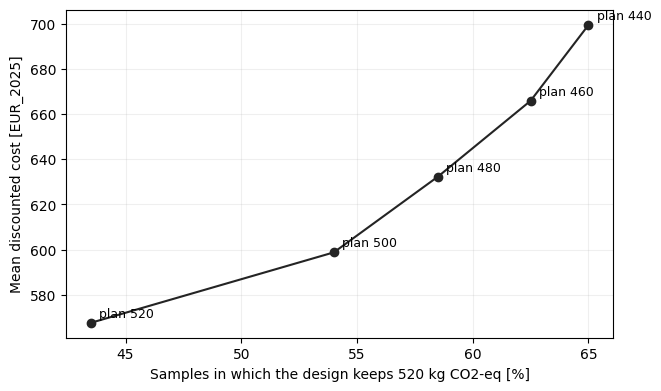

,Deterministic cost [EUR_2025],Mean cost [EUR_2025],Share of samples within 520 kg CO2-eq
Planning budget [kg CO2-eq],,,
520.000000,532.0,567.5,44%
500.000000,558.2,598.7,54%
480.000000,586.5,632.4,58%
460.000000,614.9,666.0,62%
440.000000,643.3,699.7,65%


In [28]:
fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
ax.plot(planning["Share of samples within 520 kg CO2-eq"] * 100,
        planning["Mean cost [EUR_2025]"], color="#242424", marker="o")
for budget_value, row in planning.iterrows():
    ax.annotate(f"plan {budget_value:.0f}",
                (row["Share of samples within 520 kg CO2-eq"] * 100,
                 row["Mean cost [EUR_2025]"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set(xlabel="Samples in which the design keeps 520 kg CO2-eq [%]",
       ylabel="Mean discounted cost [EUR_2025]")
ax.grid(alpha=0.2)
plt.show()
planning.style.format({
    "Deterministic cost [EUR_2025]": "{:.1f}",
    "Mean cost [EUR_2025]": "{:.1f}",
    "Share of samples within 520 kg CO2-eq": "{:.0%}",
})

A tighter planning budget raises the probability of keeping the real budget, at
a steep cost, and it levels off. Planning with 440 kg CO2-eq, close to the
climate minimum, keeps the budget in 65% of the samples, about the 66% in which
any pathway can. Beyond that no design helps; only a larger budget or less
uncertain data would.

The mean costs exceed the deterministic ones because the sampled prices and the
input demand of the advanced route are skewed upwards: their means lie above
the deterministic values.

## 8. Summary and limits

- `UncertaintySampler` turns the distributions in Brightway into Monte Carlo
  samples of the optimization inputs: foreground exchanges, parameters and their
  formulas, background databases, and prices.
- `solve_samples` shows how robust the *choice* is; `evaluate_design` shows how
  robust a *pathway* is. Together they give the regret of a deterministic design
  and the risk of missing a limit.
- Correlation follows from the data: a quantity is drawn once per sample and used
  everywhere, background snapshots share random numbers, and a price takes the
  same quantile in all snapshots.

What is not sampled: characterization factors, temporal distributions, demand,
and parameterized exchanges in background databases. Uncertainty is applied as a
relative change of the deterministic value, so an exchange with an amount of 0
cannot be varied.

Every sample is a full optimization, so the run time grows linearly with the
number of samples. For large systems, build the models with
`backend="linopy"`, see [Solving](../docs/content/solving.md#large-models).
For a design that minimizes a risk measure directly, such as the expected impact
plus a penalty on the worst samples, instead of tuning a safety margin, the
samples are the input for a sample-average or CVaR formulation.

- [Uncertainty](../docs/content/uncertainty.md): reference for the sampling and
  evaluation options.
- [Solving a series of models](../docs/content/solving.md#solving-a-series-of-models):
  `optimizer.solve_series` for sweeps and scenario comparisons, with the same
  fast path as the Monte Carlo functions.
- [Basic cost example](basic_example_econ.ipynb): the deterministic version of
  this system.